In [1]:
import numpy as np
import scipy.stats

import corner
import emcee
import dynesty

import matplotlib.pyplot as plt

In [2]:
title = "# Sampling 2: Exercise Solutions"
# Print title and setup TeX defs for both KaTeX and MathJax
import bayesian_stats_course_tools
bayesian_stats_course_tools.misc.display_markdown_and_setup_tex(title)

import matplotlib.style
matplotlib.style.use("bayesian_stats_course_tools.light")

# Sampling 2: Exercise Solutions

<!-- Define LaTeX macros -->
$\def\E{\operatorname{E}}$
$\def\Var{\operatorname{Var}}$
$\def\Cov{\operatorname{Cov}}$
$\def\dd{\mathrm{d}}$
$\def\ee{\mathrm{e}}$
$\def\Norm{\mathcal{N}}$
$\def\Uniform{\mathcal{U}}$
$\def\GP{\mathcal{GP}}$

<!-- MathJax needs them to be defined again for the non-inline environment -->
$$\def\E{\operatorname{E}}$$
$$\def\Var{\operatorname{Var}}$$
$$\def\Cov{\operatorname{Cov}}$$
$$\def\dd{\mathrm{d}}$$
$$\def\ee{\mathrm{e}}$$
$$\def\Norm{\mathcal{N}}$$
$$\def\Uniform{\mathcal{U}}$$
$$\def\GP{\mathcal{GP}}$$

We use the two targets from last week: the 1D Gamma distribution from the lecture and the 2D Gaussian from the Metropolis-Hastings exercise.

In [3]:
# 1D target from the lecture
target_distr_1d = scipy.stats.gamma(a=3, scale=1/3)

# 2D Gaussian from the Metropolis-Hastings exercise
sigma_x = 1
sigma_y = 2
rho = 0.7

mean = np.array([1, 0.5])
cov = np.array([[sigma_x**2, sigma_x*sigma_y*rho],
                [sigma_x*sigma_y*rho, sigma_y**2]])

bivariate_normal = scipy.stats.multivariate_normal(mean=mean, cov=cov)

# Exact samples, to compare your samplers against
np.random.seed(42)
true_samples = bivariate_normal.rvs(size=10_000)

A small helper to overplot several sets of samples in one corner plot:

In [4]:
def compare_corner(sample_sets, labels, weights=None):
    """Overplot several sets of 2D samples in one corner plot."""
    if weights is None:
        weights = [None]*len(sample_sets)

    fig = plt.figure()
    for i, (samples, w) in enumerate(zip(sample_sets, weights)):
        if w is None:
            w = np.ones(len(samples))   # equally weighted samples
        corner.corner(
            samples, weights=w/np.sum(w),
            bins=25, smooth=1.0, color=f"C{i}",  # light smoothing for fewer, noisy samples
            range=[(-3, 5), (-6, 7)],
            levels=1-np.exp(-0.5*np.array([1, 2])**2),  # 1 and 2 sigma contours in 2D
            labels=["$x$", "$y$"],
            fig=fig,
        )
    # Add a legend
    for i, label in enumerate(labels):
        fig.axes[0].plot([], [], c=f"C{i}", label=label)
    fig.axes[0].legend(loc="upper left", bbox_to_anchor=(1, 1), frameon=False)
    return fig

---
## Exercise 1: Slice sampling

### 1.1 Slice sampling in 1D

We follow the algorithm from the lecture, but work with $\ln p(x)$. The height of the slice is then $\ln u = \ln p(x_t) + \ln v$, with $v\sim\Uniform(0, 1)$.

We write one update as its own function, so we can reuse it in 2D.

In [5]:
def slice_step(log_p, x, w):
    """One slice sampling update of the 1D point x, with step size w."""
    # 1. Height of the slice, in log space
    log_u = log_p(x) + np.log(np.random.uniform())

    # 2. Place an interval of width w randomly around x ...
    r = np.random.uniform()
    left = x - r*w
    right = x + (1 - r)*w
    # ... and step out until both ends are outside the slice
    while log_p(left) > log_u:
        left = left - w
    while log_p(right) > log_u:
        right = right + w

    # 3. Draw a point in the interval. If it is outside the slice,
    # shrink the interval towards x and try again
    while True:
        x_new = np.random.uniform(left, right)
        if log_p(x_new) > log_u:
            return x_new       # inside the slice: accept
        if x_new > x:
            right = x_new
        else:
            left = x_new


def slice_sample_1d(log_p, x0, w, n):
    """Draw n samples with slice sampling, starting at x0."""
    samples = np.zeros(n)
    x = x0
    for i in range(n):
        x = slice_step(log_p, x, w)
        samples[i] = x
    return samples

To see how much work the sampler does, we count the evaluations of $\ln p(x)$ with a global counter:

In [6]:
n_evals = 0

def log_p_gamma(x):
    """Log PDF of the Gamma target. Also counts the number of calls."""
    global n_evals
    n_evals += 1
    return target_distr_1d.logpdf(x)

Evaluations of p(x) per sample: 6.2


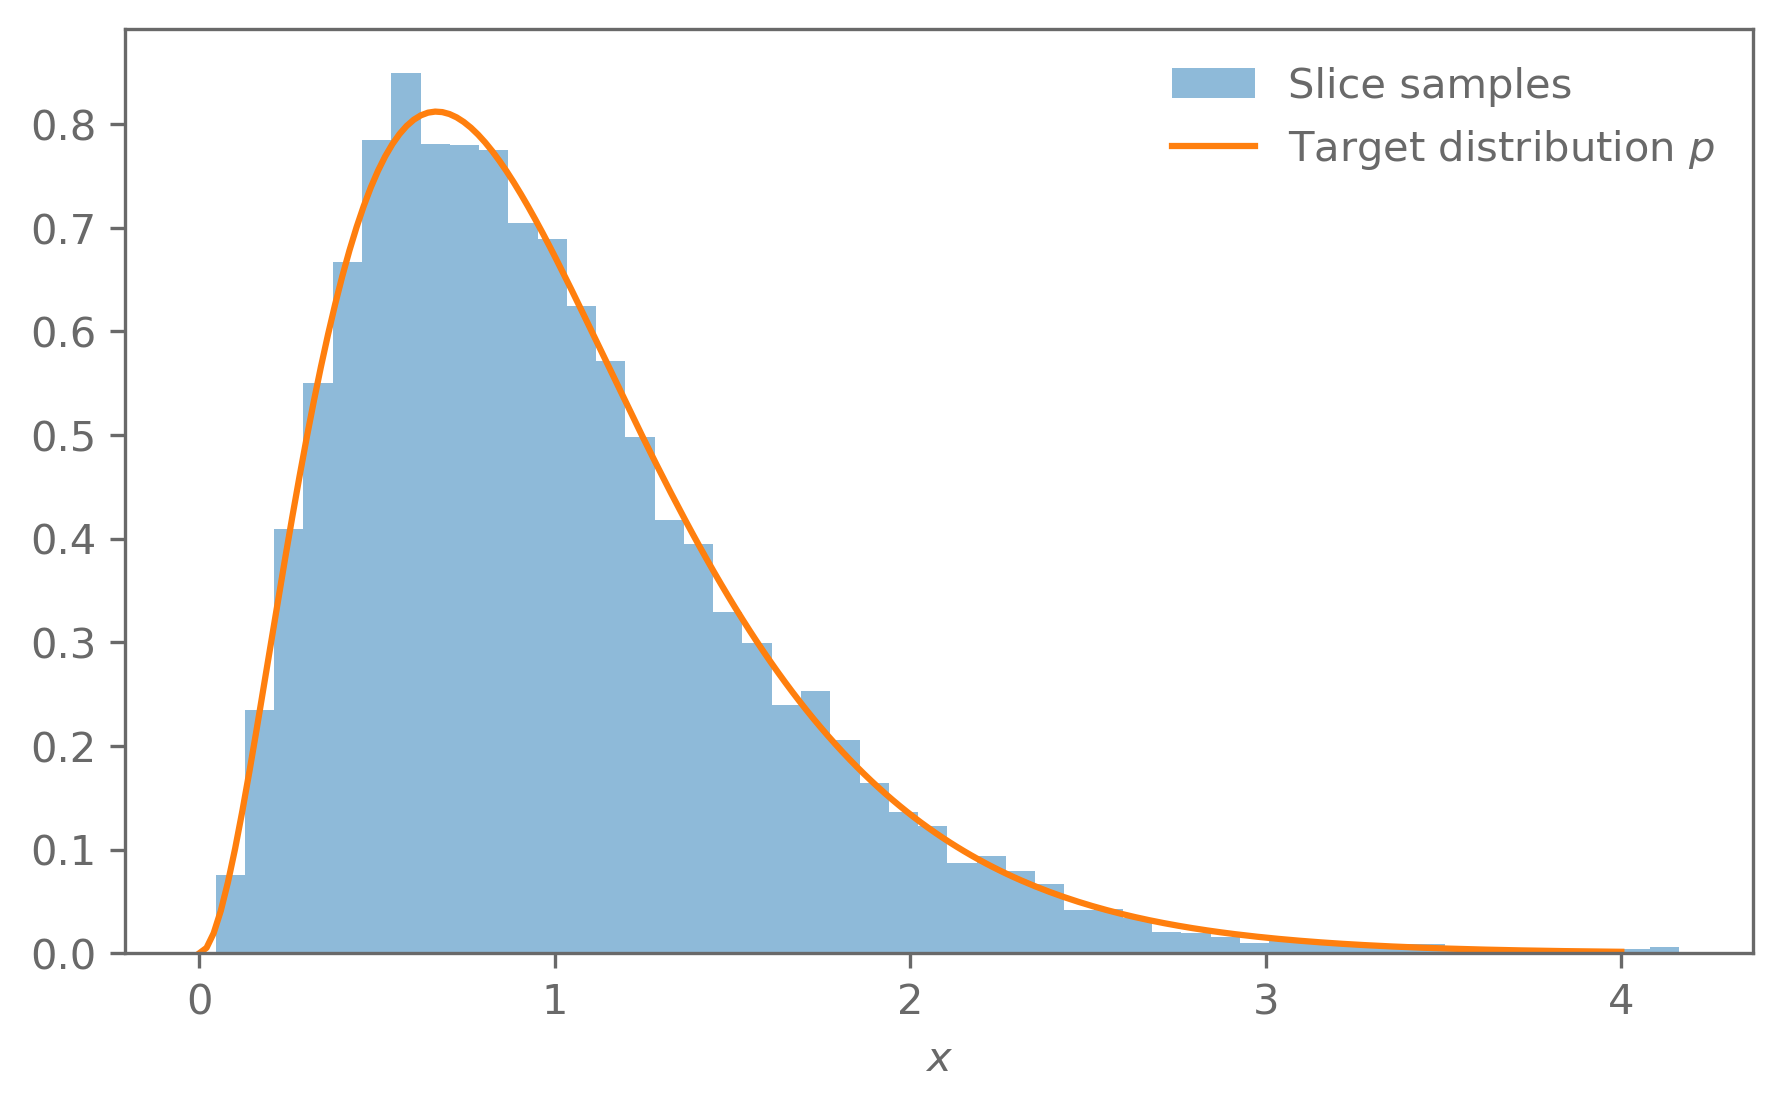

In [7]:
np.random.seed(1)

n_evals = 0
samples = slice_sample_1d(log_p_gamma, x0=1.0, w=1, n=10_000)
print(f"Evaluations of p(x) per sample: {n_evals/len(samples):.1f}")

grid = np.linspace(0, 4, 200)
plt.hist(samples, bins=50, density=True, alpha=0.5, label="Slice samples")
plt.plot(grid, target_distr_1d.pdf(grid), label="Target distribution $p$")
plt.xlabel("$x$")
plt.legend(frameon=False);

The samples follow the PDF.

### 1.2 The step size $w$

We run the sampler again with $w = 0.01, 1, 100$:

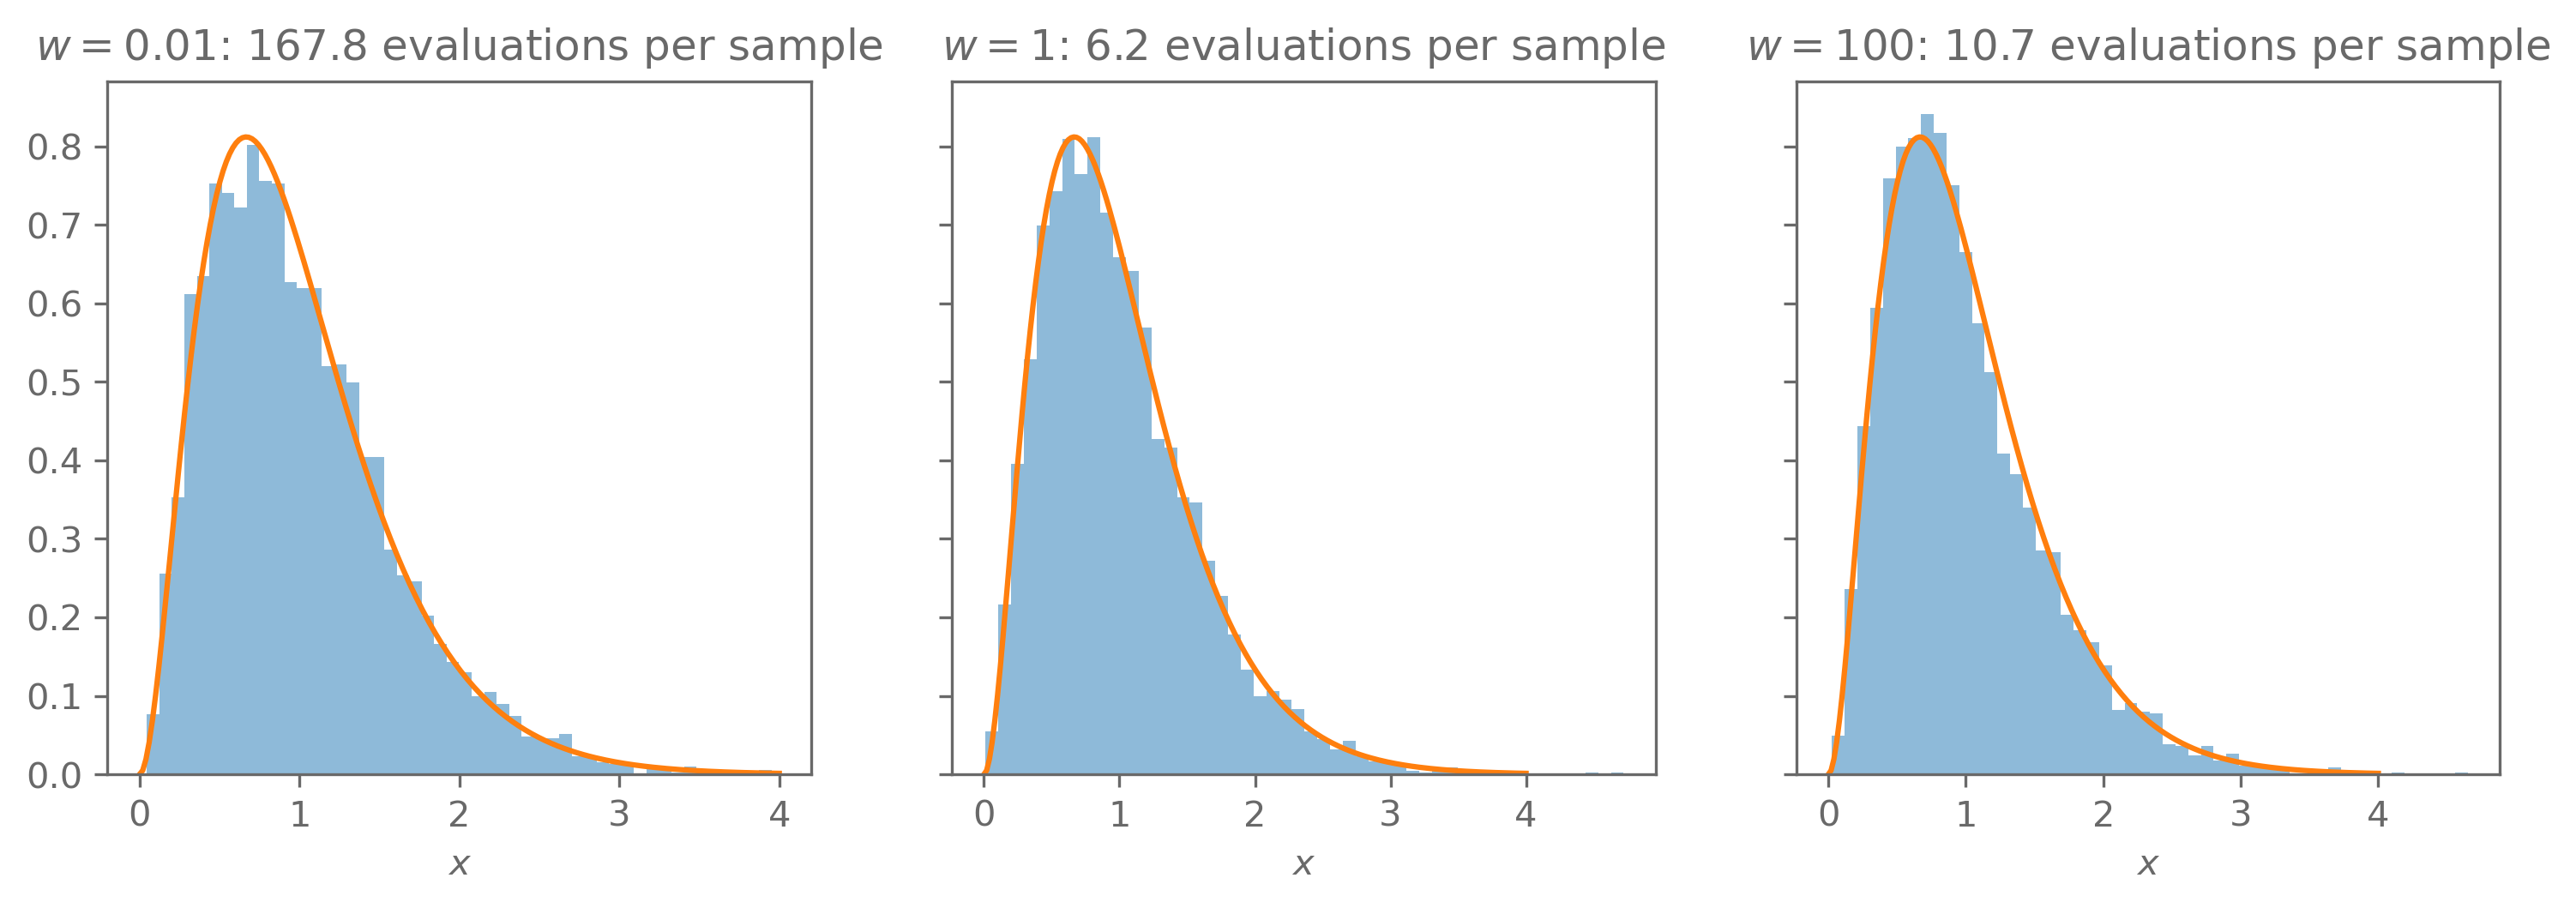

In [8]:
np.random.seed(2)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True)
for ax, w in zip(axes, [0.01, 1, 100]):
    n_evals = 0
    samples = slice_sample_1d(log_p_gamma, x0=1.0, w=w, n=5000)

    ax.hist(samples, bins=50, density=True, alpha=0.5)
    ax.plot(grid, target_distr_1d.pdf(grid))
    ax.set_title(f"$w={w}$: {n_evals/len(samples):.1f} evaluations per sample")
    ax.set_xlabel("$x$")

All three step sizes give the correct distribution, only the cost changes:
- $w = 0.01$: many stepping-out steps, because the interval grows very slowly.
- $w = 100$: many shrinking steps, because the interval starts far too wide.
- $w = 1$, close to the width of the distribution, is the cheapest.

### 1.3 Slice sampling in 2D

We update one coordinate at a time, keeping the other one fixed. Each update is a 1D slice step, so we reuse `slice_step`:

In [9]:
def slice_sample_nd(log_p, x0, w, n):
    """Slice sampling in n dimensions, updating one coordinate at a time."""
    x = np.array(x0, dtype=float)
    samples = np.zeros((n, len(x)))
    for i in range(n):
        for k in range(len(x)):
            # log p as a function of coordinate k only,
            # with all the other coordinates fixed
            def log_p_k(x_k):
                x_trial = x.copy()
                x_trial[k] = x_k
                return log_p(x_trial)

            x[k] = slice_step(log_p_k, x[k], w)
        samples[i] = x
    return samples

Evaluations of p(x) per sample: 15.6


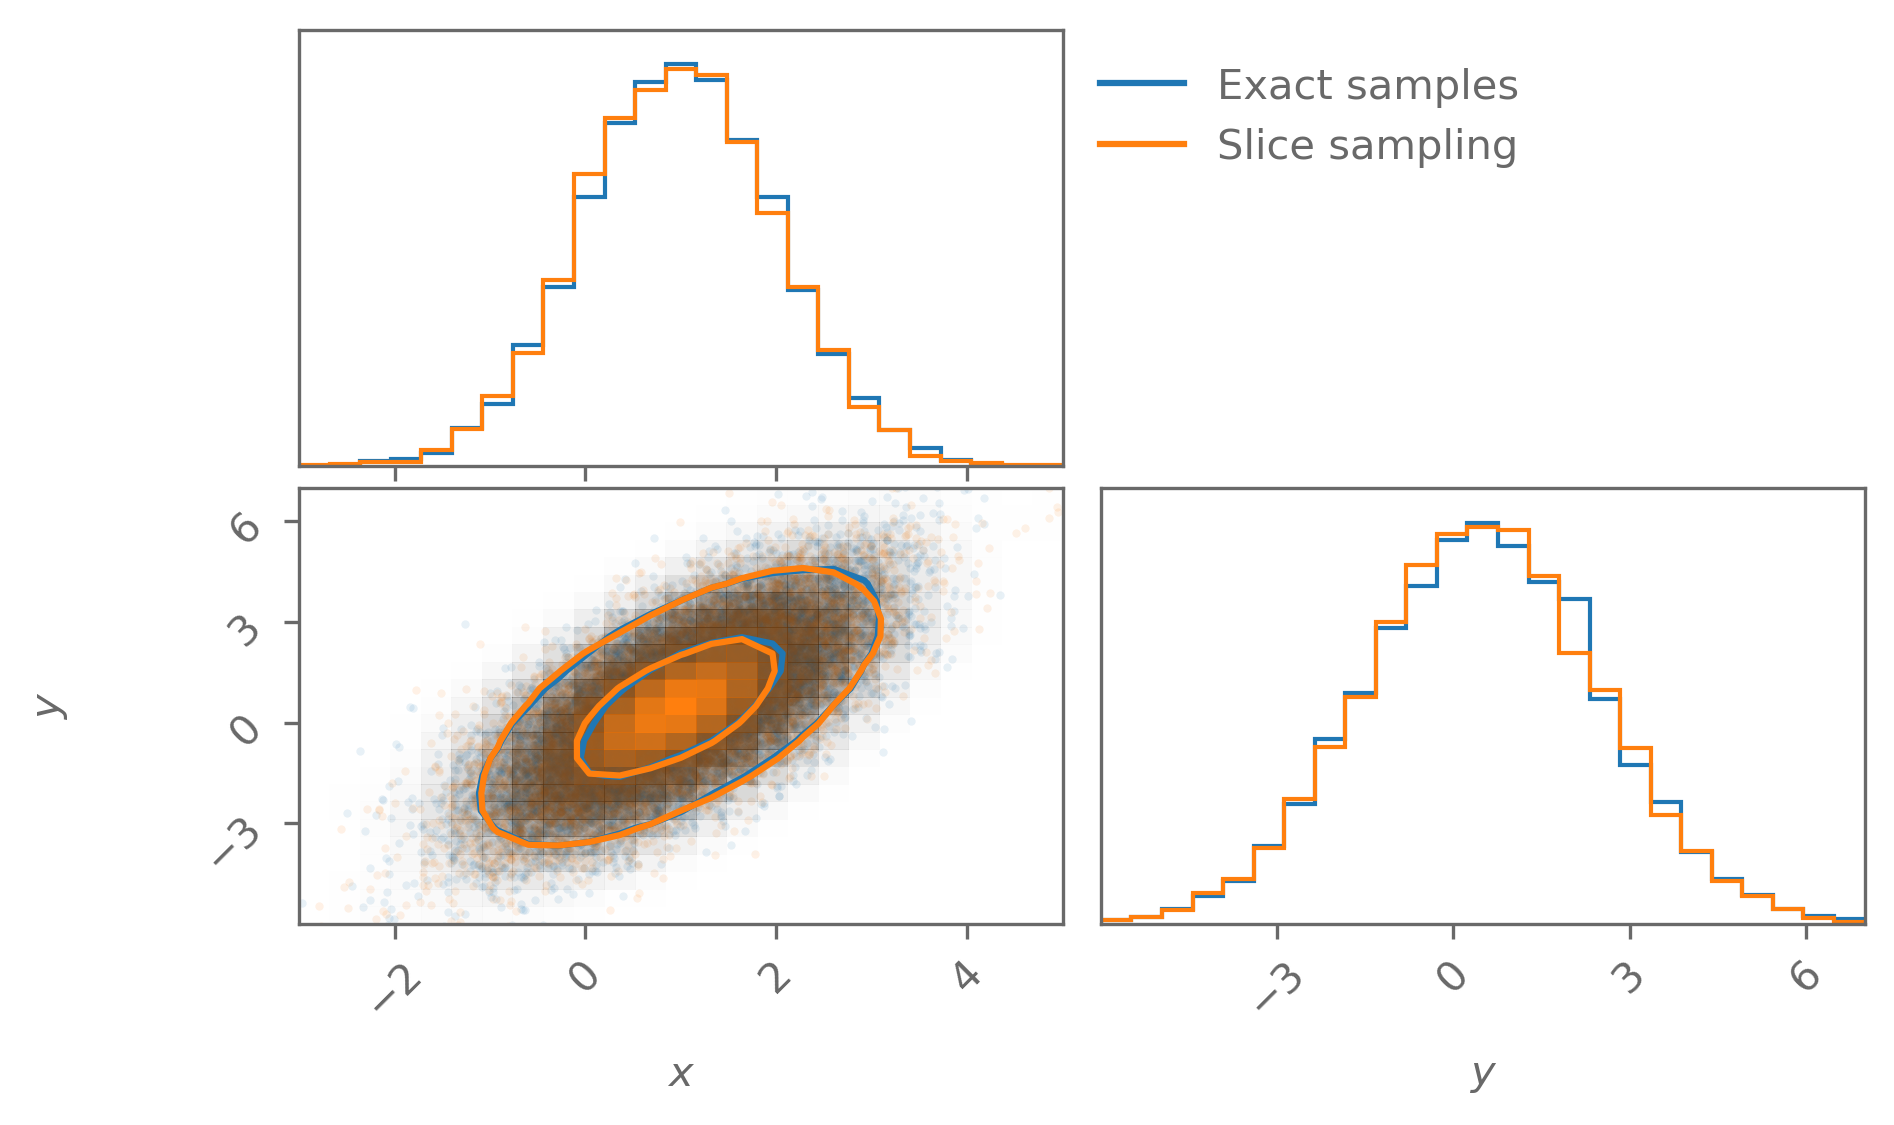

In [10]:
def log_p_gauss(x):
    """Log PDF of the 2D Gaussian target. Also counts the number of calls."""
    global n_evals
    n_evals += 1
    return bivariate_normal.logpdf(x)

np.random.seed(3)

n_evals = 0
slice_samples = slice_sample_nd(log_p_gauss, x0=[0, 0], w=1, n=10_000)
print(f"Evaluations of p(x) per sample: {n_evals/len(slice_samples):.1f}")

compare_corner([true_samples, slice_samples], ["Exact samples", "Slice sampling"]);

The slice samples agree with the exact samples.

---
## Exercise 2: Burn-in and auto-correlation

### 2.1 Starting far away from the mean

For Metropolis-Hastings we use a short version of `run_metropolis` from the week 5 solutions, with a Gaussian proposal around the current point. This proposal is symmetric, so we accept with probability $\min(1, p(x')/p(x_t))$.

We use an improper flat prior, so any starting point is allowed.

In [11]:
def metropolis_hastings(log_p, x0, step, n):
    """Metropolis-Hastings with a Gaussian proposal of width step around the current point."""
    x = np.array(x0, dtype=float)
    log_p_x = log_p(x)
    samples = np.zeros((n, len(x)))
    n_accept = 0
    for i in range(n):
        # Propose a new point around the current one
        x_new = x + step*np.random.normal(size=len(x))
        log_p_new = log_p(x_new)

        # Accept with probability min(1, p(x_new)/p(x))
        if np.log(np.random.uniform()) < log_p_new - log_p_x:
            x = x_new
            log_p_x = log_p_new
            n_accept += 1
        samples[i] = x
    print(f"Acceptance rate: {n_accept/n:.2f}")
    return samples

In [12]:
np.random.seed(4)
x_start = [10, -10]
n_steps = 20_000

n_evals = 0
mh_chain = metropolis_hastings(log_p_gauss, x_start, step=1, n=n_steps)
mh_evals_per_step = n_evals/n_steps

n_evals = 0
slice_chain = slice_sample_nd(log_p_gauss, x_start, w=1, n=n_steps)
slice_evals_per_step = n_evals/n_steps

print(f"Evaluations of p(x) per step: MH {mh_evals_per_step:.1f}, slice {slice_evals_per_step:.1f}")

Acceptance rate: 0.55


Evaluations of p(x) per step: MH 1.0, slice 15.6


The first 500 steps of each chain. The dashed lines show the mean of the target.

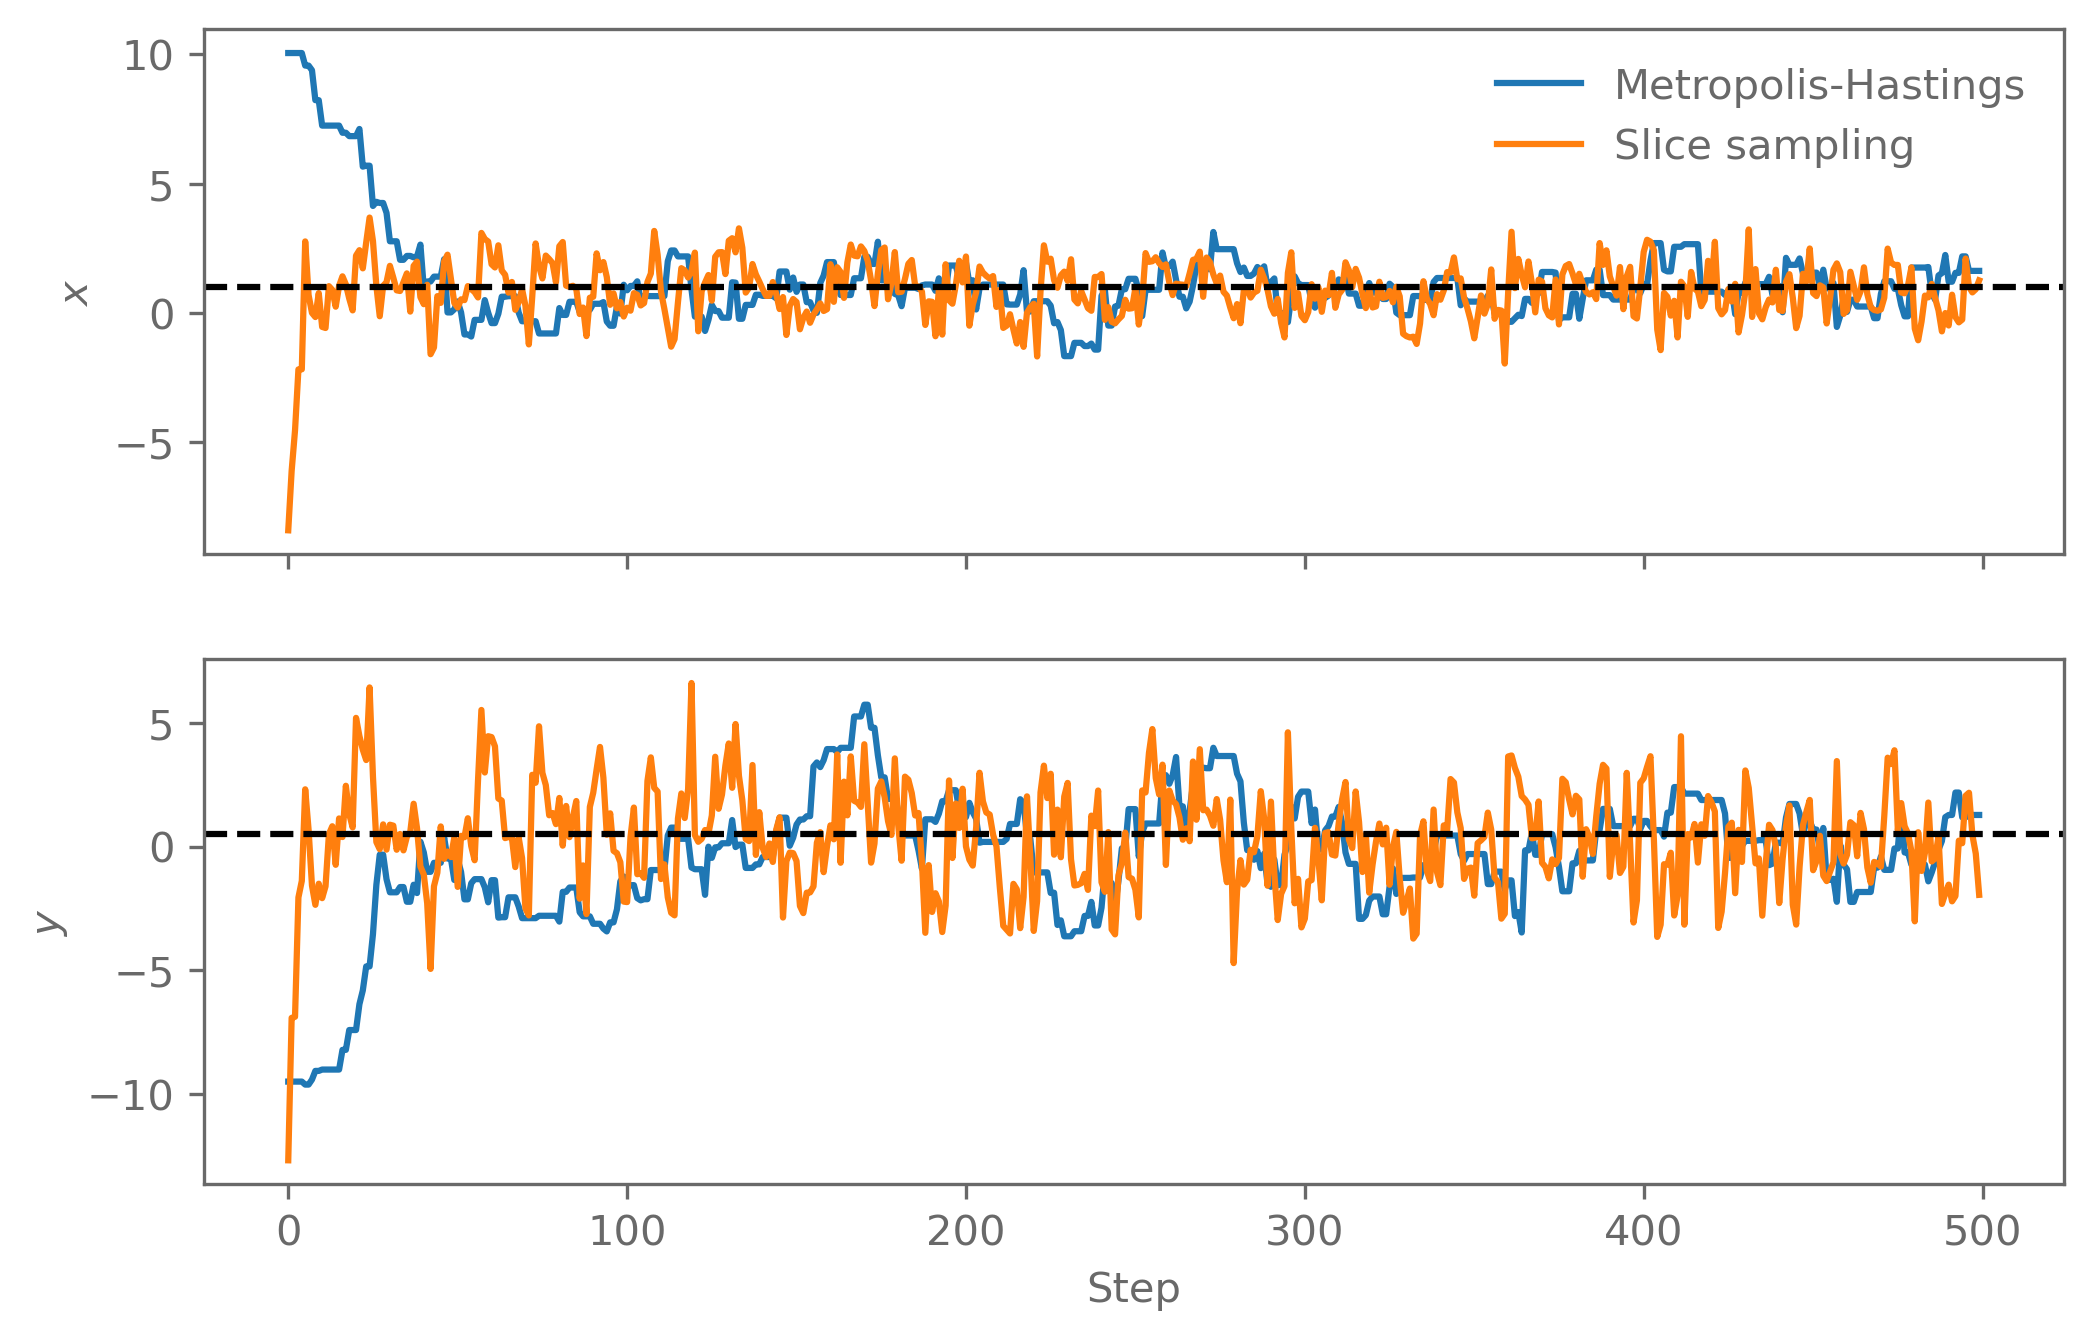

In [13]:
fig, axes = plt.subplots(2, 1, figsize=(8, 5), sharex=True)
for k, (ax, name) in enumerate(zip(axes, ["$x$", "$y$"])):
    ax.plot(mh_chain[:500, k], label="Metropolis-Hastings")
    ax.plot(slice_chain[:500, k], label="Slice sampling")
    ax.axhline(mean[k], c="k", ls="--")
    ax.set_ylabel(name)
axes[0].legend(frameon=False)
axes[1].set_xlabel("Step");

Both chains reach the target quickly: Metropolis-Hastings after about 50 steps, slice sampling after about 10. To be safe, we remove the first 1000 steps as burn-in.

The Metropolis-Hastings chain often stays at the same point (rejected proposals) and wanders slowly, while the slice sampling chain jumps around much more.

### 2.2 Auto-correlation time

A chain of $N$ steps has about $N/\tau$ independent samples.

In [14]:
burn_in = 1000

for name, chain in [("Metropolis-Hastings", mh_chain), ("Slice sampling", slice_chain)]:
    chain = chain[burn_in:]
    # Auto-correlation time of each coordinate
    tau = [emcee.autocorr.integrated_time(chain[:, k]) [0] for k in range(2)]
    n_independent = len(chain)/max(tau)
    print(f"{name}: tau_x = {tau[0]:.1f}, tau_y = {tau[1]:.1f}, "
          f"about {n_independent:.0f} independent samples")

Metropolis-Hastings: tau_x = 27.1, tau_y = 41.2, about 462 independent samples
Slice sampling: tau_x = 3.1, tau_y = 3.0, about 6160 independent samples


Slice sampling has a much shorter auto-correlation time, so it gives many more independent samples per step.

But each slice step needs about 16 evaluations of $p(x)$, while Metropolis-Hastings needs only one. Per evaluation of $p(x)$, the two samplers are about equally efficient here.

---
## Exercise 3: Nested sampling

### 3.1 Implementation

We follow the algorithm from the lecture, with two simplifications:
- New live points come from rejection sampling: draw from the prior until $L(\theta) > L_i^*$.
- Each dead point gets the weight $\Delta X_i = X_{i-1} - X_i$ instead of the trapezoidal rule, with $X_i = t^i$ and $t = n_\mathrm{live}/(n_\mathrm{live}+1)$.

We stop when the live points can add less than 1% to $Z$, and then add the remaining live points, each with weight $X_i/n_\mathrm{live}$. Everything is done in log space: `np.logaddexp(a, b)` computes $\ln(e^a + e^b)$.

In [15]:
def nested_sampling(log_L, prior_sample, n_live, tol=0.01):
    """Nested sampling with rejection sampling from the prior.

    Returns log Z, the dead points, their posterior weights, and the
    number of tries needed to find each new live point.
    """
    # 1. Live points from the prior
    live_points = prior_sample(n_live)
    live_log_L = np.array([log_L(theta) for theta in live_points])

    log_t = np.log(n_live/(n_live + 1))   # volume shrinks by t each iteration
    log_X = 0.0                           # X_0 = 1
    log_Z = -np.inf                       # Z = 0 at the start

    dead_points, dead_log_L, dead_log_dX = [], [], []
    n_tries = []

    while True:
        # 2. The live point with the lowest likelihood becomes a dead point
        i_min = np.argmin(live_log_L)
        log_L_star = live_log_L[i_min]

        # 4. Its weight is Delta X = X_{i-1} - X_i = X_{i-1} (1 - t)
        log_dX = log_X + np.log(1 - np.exp(log_t))
        log_Z = np.logaddexp(log_Z, log_L_star + log_dX)
        log_X = log_X + log_t

        dead_points.append(live_points[i_min].copy())
        dead_log_L.append(log_L_star)
        dead_log_dX.append(log_dX)

        # 3. Replace it with a prior sample with a higher likelihood
        tries = 0
        while True:
            theta = prior_sample(1)[0]
            tries += 1
            if log_L(theta) > log_L_star:
                break
        live_points[i_min] = theta
        live_log_L[i_min] = log_L(theta)
        n_tries.append(tries)

        # 5. Stop if the live points can only add a small fraction to Z
        if np.max(live_log_L) + log_X < np.log(tol) + log_Z:
            break

    # Add the remaining live points, each with weight X/n_live
    for theta, log_L_live in zip(live_points, live_log_L):
        log_dX = log_X - np.log(n_live)
        log_Z = np.logaddexp(log_Z, log_L_live + log_dX)
        dead_points.append(theta)
        dead_log_L.append(log_L_live)
        dead_log_dX.append(log_dX)

    # Posterior weights p_i = L_i Delta X_i / Z
    weights = np.exp(np.array(dead_log_L) + np.array(dead_log_dX) - log_Z)

    return log_Z, np.array(dead_points), weights, np.array(n_tries)

Likelihood: the 2D Gaussian. Prior: uniform on $[-7, 7]^2$.

In [16]:
def log_L_gauss(theta):
    return bivariate_normal.logpdf(theta)

def prior_sample_box(n):
    """n samples from the uniform prior on [-7, 7]^2."""
    return np.random.uniform(-7, 7, size=(n, 2))

np.random.seed(5)
log_Z, dead_points, ns_weights, n_tries = nested_sampling(
    log_L_gauss, prior_sample_box, n_live=200)
print(f"Nested sampling: ln Z = {log_Z:.3f}")

Nested sampling: ln Z = -5.287


### 3.2 Exact evidence

The prior is $1/14^2$ inside the box, and almost all of the Gaussian lies inside the box, so
$$
    Z = \frac{1}{14^2}\int_\mathrm{box} L(\theta)\dd\theta \approx \frac{1}{14^2}\,.
$$
We check that the Gaussian is inside the box with the exact samples:

In [17]:
inside_box = np.all(np.abs(true_samples) < 7, axis=1)
print(f"Fraction of the Gaussian inside the box: {np.mean(inside_box):.4f}")

log_Z_exact = -np.log(14**2)
print(f"Exact:           ln Z = {log_Z_exact:.3f}")
print(f"Nested sampling: ln Z = {log_Z:.3f}")

Fraction of the Gaussian inside the box: 0.9991
Exact:           ln Z = -5.278
Nested sampling: ln Z = -5.287


To see how precise a single run is, we repeat it with 10 seeds:

In [18]:
log_Z_runs = []
for seed in range(10):
    np.random.seed(100 + seed)
    log_Z_run, _, _, _ = nested_sampling(log_L_gauss, prior_sample_box, n_live=200)
    log_Z_runs.append(log_Z_run)

print(f"ln Z over 10 runs: {np.mean(log_Z_runs):.3f} ± {np.std(log_Z_runs):.3f}")
print(f"Exact:             {log_Z_exact:.3f}")

ln Z over 10 runs: -5.220 ± 0.083
Exact:             -5.278


The run-to-run scatter is about 0.08, and the exact value lies within this scatter.

### 3.3 Number of tries per new live point

Total number of likelihood evaluations: 389729


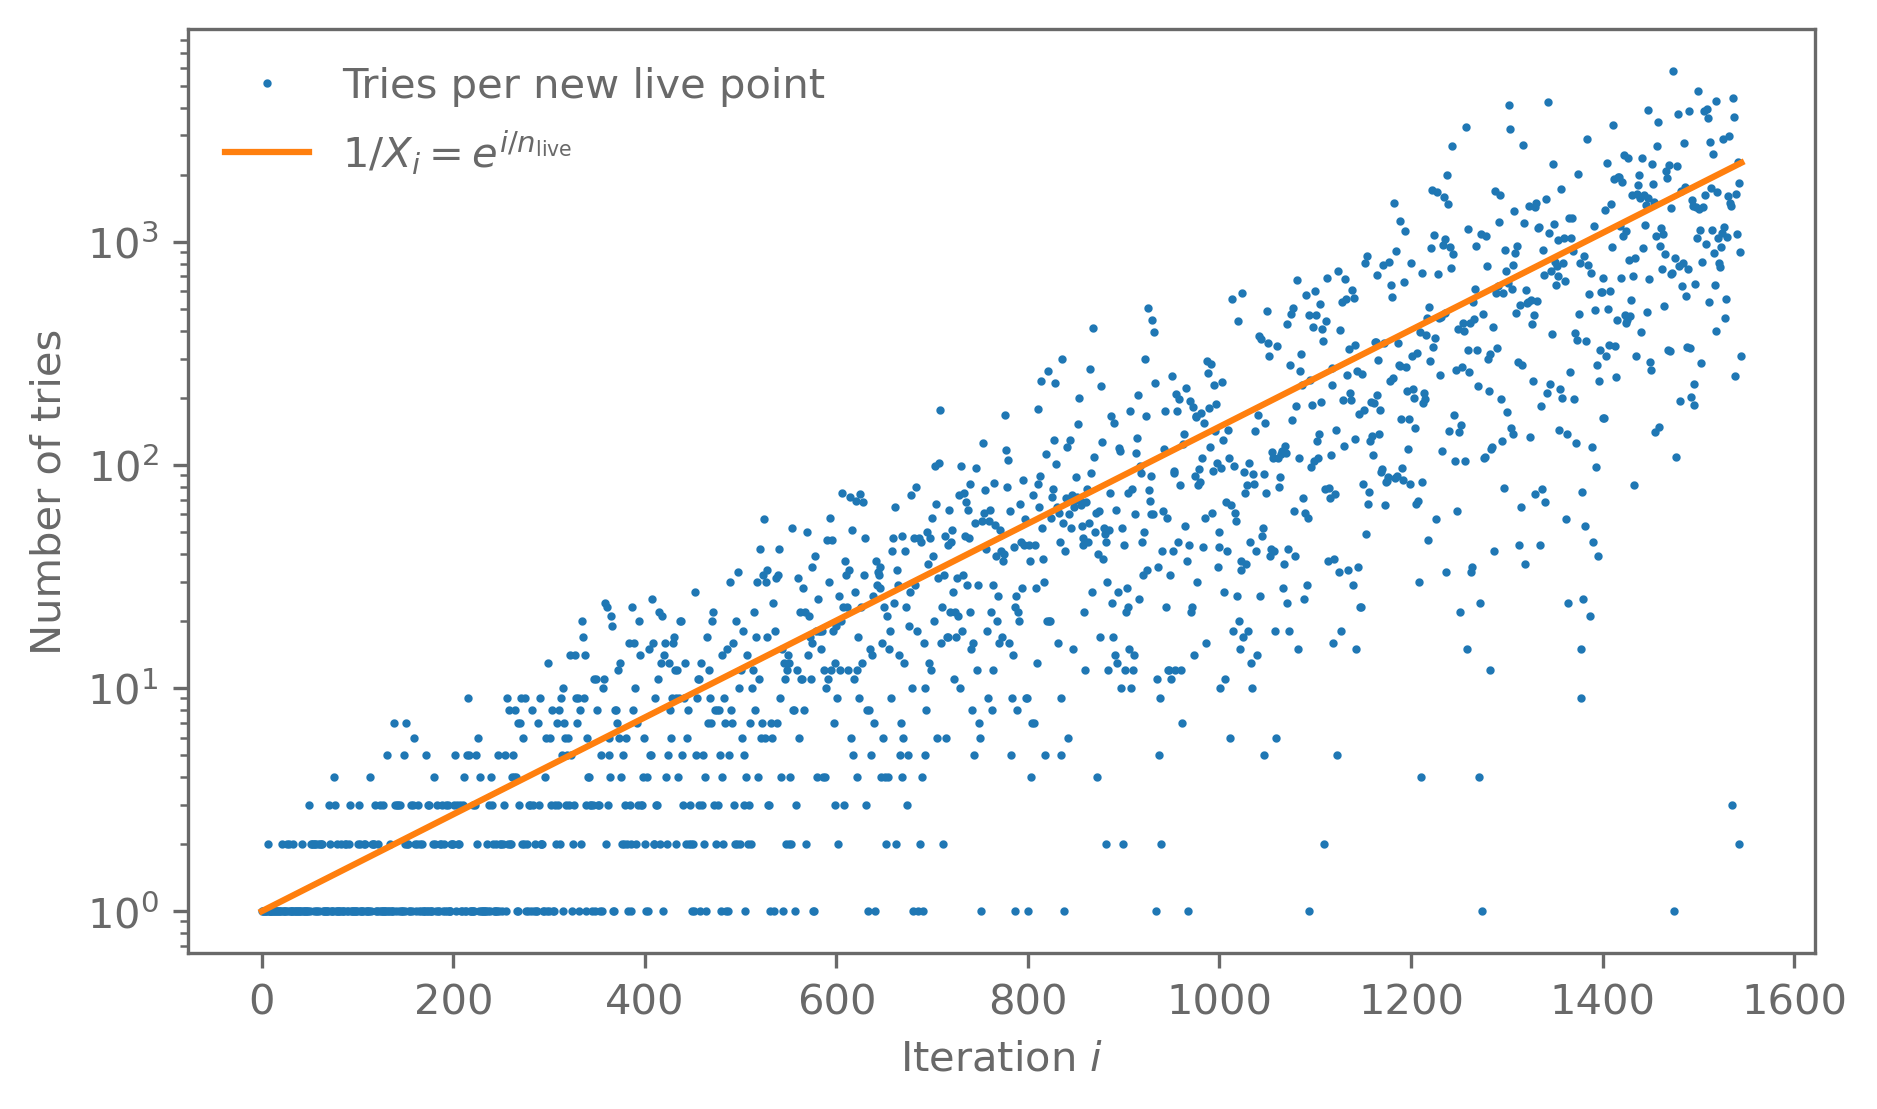

In [19]:
i = np.arange(len(n_tries))

plt.semilogy(i, n_tries, ".", ms=2, label="Tries per new live point")
plt.semilogy(i, np.exp(i/200), label=r"$1/X_i = e^{i/n_\mathrm{live}}$")
plt.xlabel("Iteration $i$")
plt.ylabel("Number of tries")
plt.legend(frameon=False)
print(f"Total number of likelihood evaluations: {np.sum(n_tries)}")

The number of tries grows exponentially. A prior draw is accepted with probability $X_i$, the prior volume with $L > L_i^*$, and this volume shrinks in every iteration.

In more dimensions, the high-likelihood region is a much smaller part of the prior (curse of dimensionality, week 5), so rejection sampling becomes hopeless. Real nested sampling codes use smarter methods, for example slice sampling, to find new live points.

### 3.4 Posterior samples

The dead points, weighted with $p_i = L_i^*\Delta X_i/Z$, are posterior samples:

Posterior mean, nested sampling: [0.9858091  0.42754968]
Posterior mean, exact samples:   [0.99232764 0.49478202]


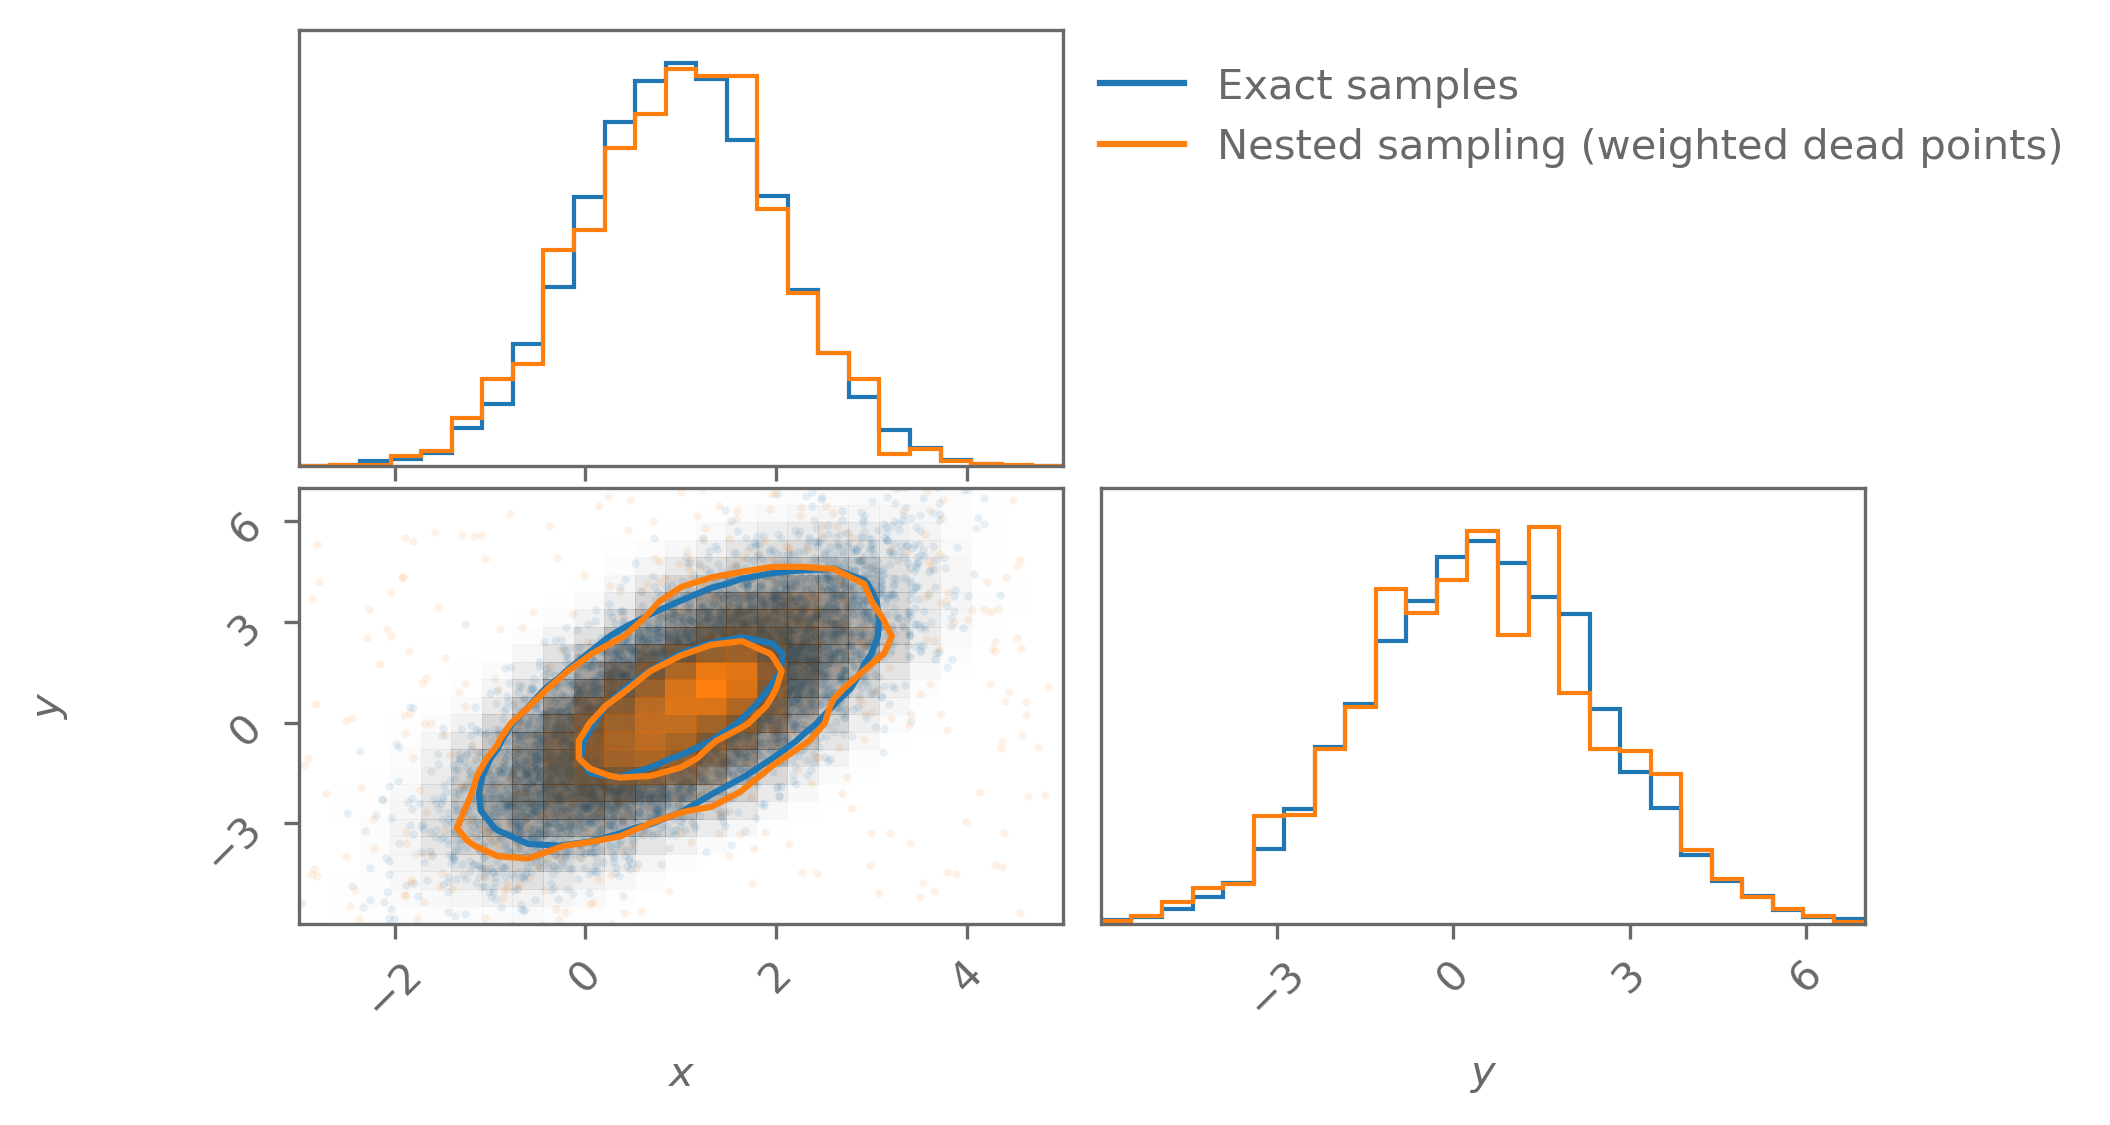

In [20]:
compare_corner(
    [true_samples, dead_points],
    ["Exact samples", "Nested sampling (weighted dead points)"],
    weights=[None, ns_weights],
);

print("Posterior mean, nested sampling:", np.average(dead_points, weights=ns_weights, axis=0))
print("Posterior mean, exact samples:  ", np.mean(true_samples, axis=0))

The weighted dead points agree with the exact samples. The histograms are noisier, because many dead points have very small weights.

---
## Exercise 4: emcee and dynesty

### 4.1 emcee

`emcee` needs the log posterior: $-\infty$ outside the box, and the log likelihood inside (the constant prior can be dropped).

In [21]:
def log_posterior_box(theta):
    if np.any(np.abs(theta) > 7):
        return -np.inf
    return bivariate_normal.logpdf(theta)

np.random.seed(6)
n_walker = 10
theta_init = 0.1*np.random.normal(size=(n_walker, 2))  # start the walkers close to 0

sampler = emcee.EnsembleSampler(nwalkers=n_walker, ndim=2, log_prob_fn=log_posterior_box)
sampler.run_mcmc(theta_init, nsteps=5000)

tau = sampler.get_autocorr_time()
print("Auto-correlation time:", tau)

# Remove the burn-in (a few auto-correlation times) and thin the chain
emcee_samples = sampler.get_chain(discard=int(5*max(tau)), thin=int(max(tau)/2), flat=True)
print("Number of samples:", len(emcee_samples))

Auto-correlation time: [39.15683819 34.90863955]
Number of samples: 2520


### 4.2 dynesty

`dynesty` needs a `prior_transform` that maps the unit cube to the prior. For $\Uniform(-7, 7)$ this is $\theta = 14u - 7$.

In [22]:
def prior_transform_box(u):
    return 14*u - 7

dynesty_sampler = dynesty.NestedSampler(
    loglikelihood=log_L_gauss,
    prior_transform=prior_transform_box,
    ndim=2,
    nlive=500,
    rstate=np.random.default_rng(7),  # seed for reproducibility
)
dynesty_sampler.run_nested(print_progress=False)
dynesty_results = dynesty_sampler.results
dynesty_results.summary()

# Equally weighted posterior samples
dynesty_samples = dynesty_results.samples_equal()

Summary
nlive: 500
niter: 1957
ncall: 18141
eff(%): 13.544
logz: -5.264 +/-  0.131


### 4.3 Comparison

The weighted dead points of our nested sampler are noisy (see 3.4), so we leave them out of this plot.

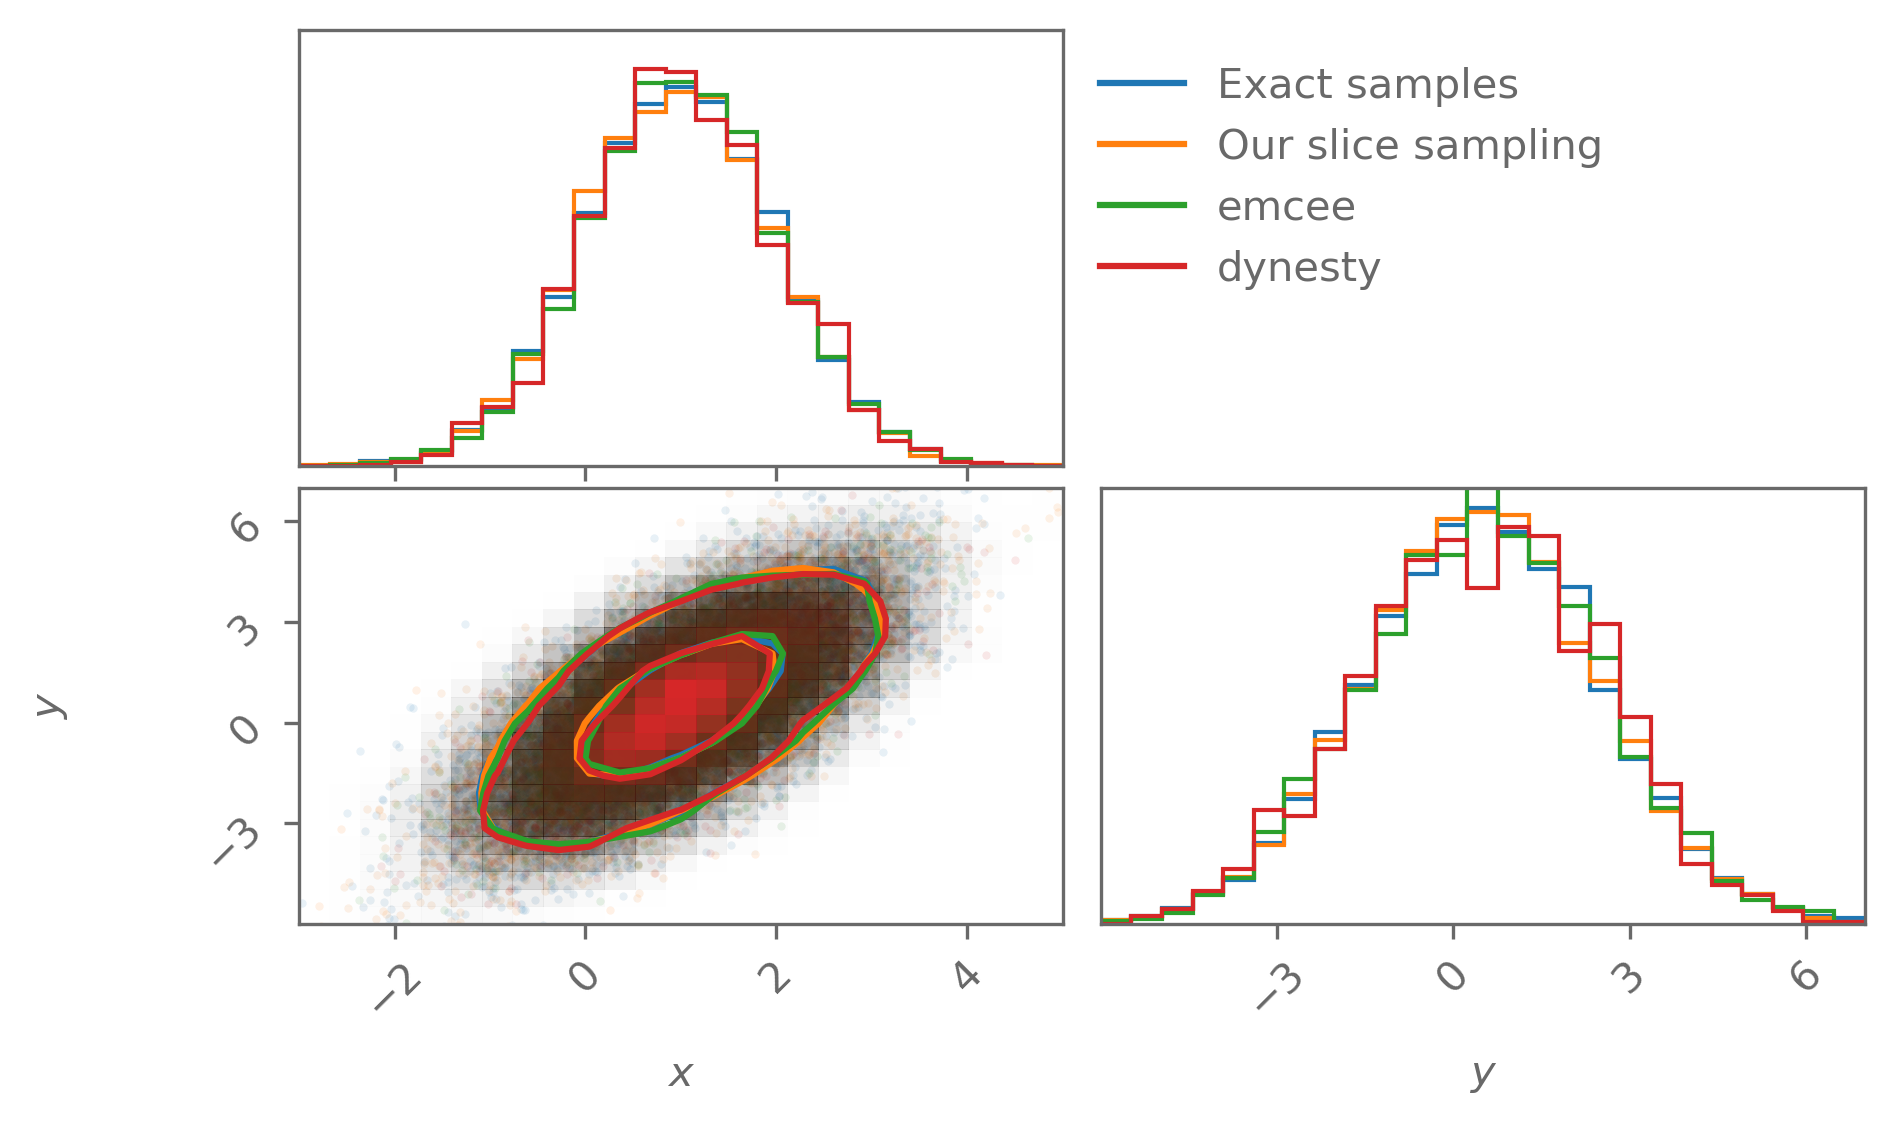

In [23]:
compare_corner(
    [true_samples, slice_samples, emcee_samples, dynesty_samples],
    ["Exact samples", "Our slice sampling", "emcee", "dynesty"],
);

In [24]:
print(f"Exact:               ln Z = {log_Z_exact:.3f}")
print(f"Our nested sampling: ln Z = {np.mean(log_Z_runs):.3f} ± {np.std(log_Z_runs):.3f}  (10 runs)")
print(f"dynesty:             ln Z = {dynesty_results.logz[-1]:.3f} ± {dynesty_results.logzerr[-1]:.3f}")

Exact:               ln Z = -5.278
Our nested sampling: ln Z = -5.220 ± 0.083  (10 runs)
dynesty:             ln Z = -5.264 ± 0.131


All samplers agree with the exact samples, and both nested samplers find the exact $\ln Z$ within their uncertainties.

---
## Exercise 5: Model comparison

### 5.1 Linear vs. quadratic model on `data_2.txt`

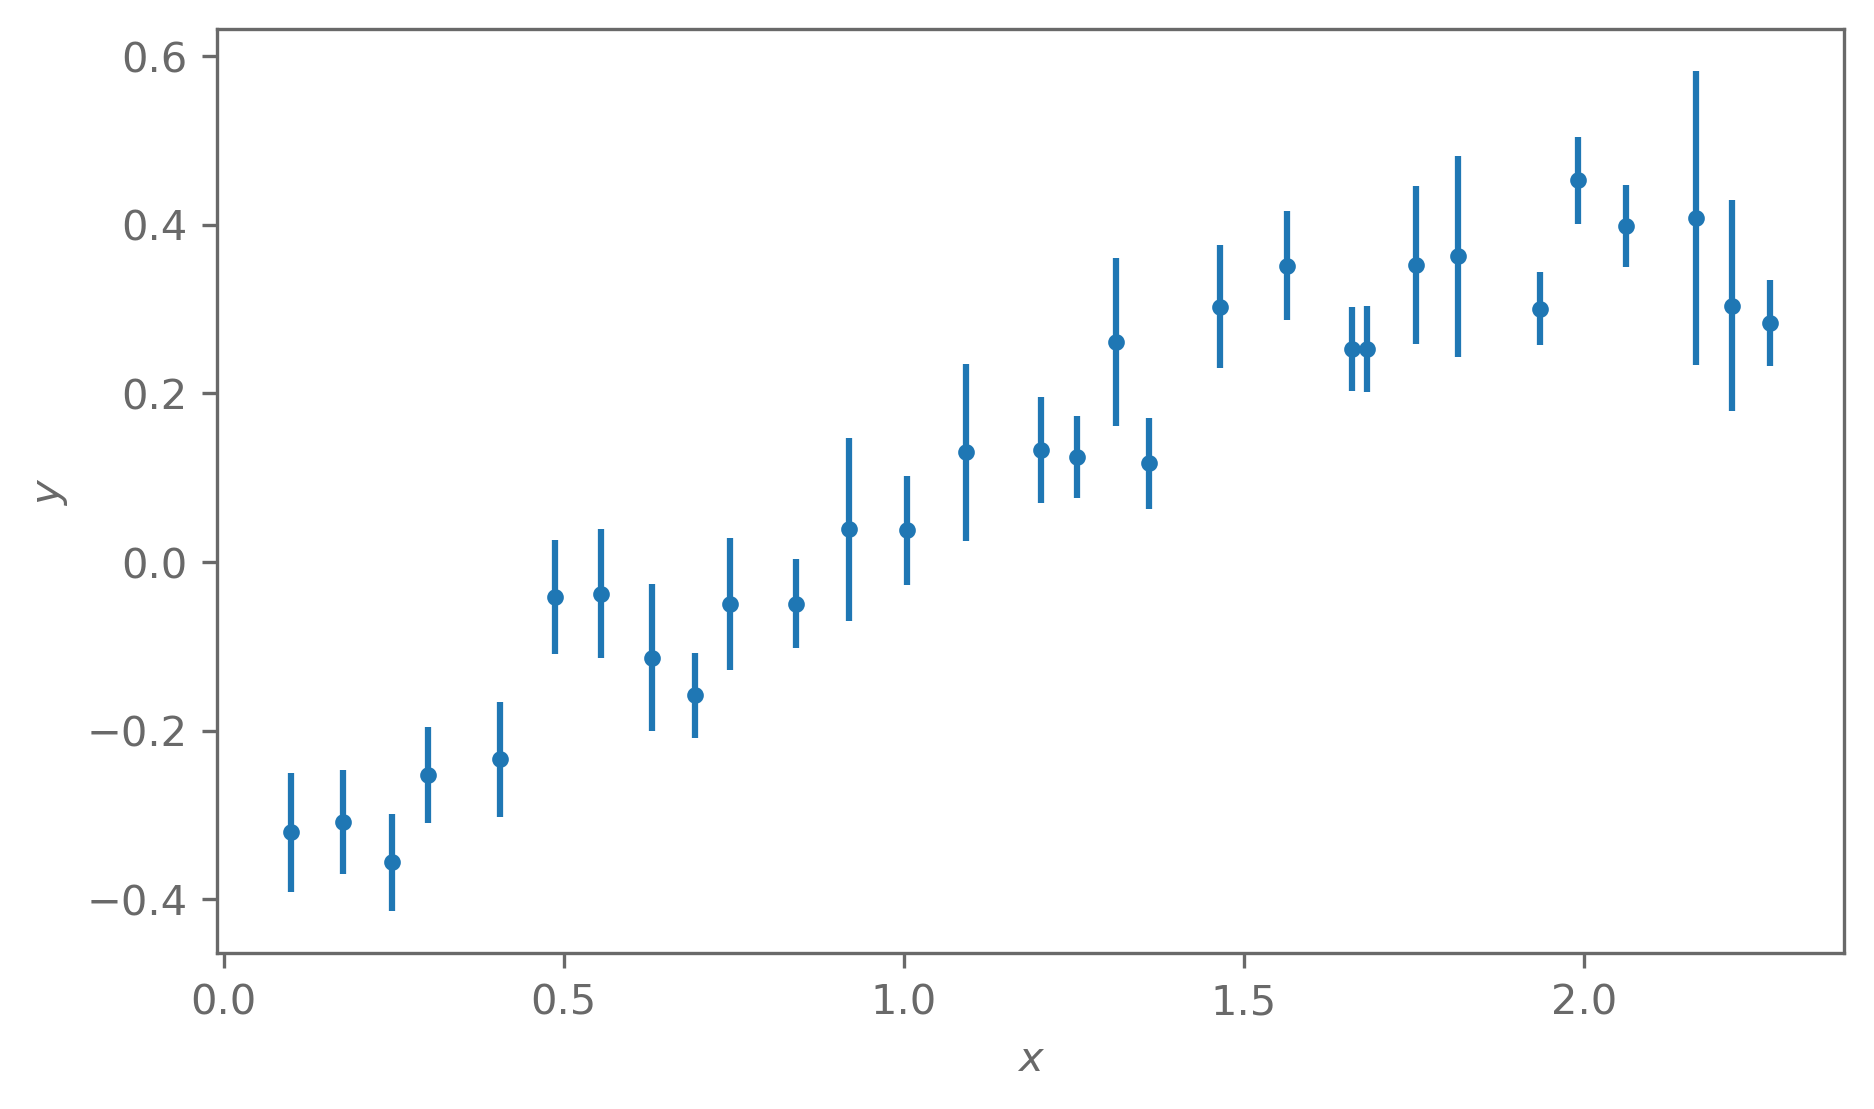

In [25]:
x, y, y_err = np.loadtxt("../lectures/data/linear_fits/data_2.txt", unpack=True)

plt.errorbar(x, y, y_err, fmt=".")
plt.xlabel("$x$")
plt.ylabel("$y$");

To compare evidences, the likelihood must be normalised, so we keep the term $-\frac{1}{2}\sum_i\ln(2\pi\sigma_{y_i}^2)$.

In [26]:
def linear_model(theta, x):
    m, b = theta
    return m*x + b

def quadratic_model(theta, x):
    a, b, c = theta
    return a*x**2 + b*x + c

def log_likelihood(theta, model, x, y, y_err):
    mu = model(theta, x)
    return (
        -0.5*np.sum((y - mu)**2/y_err**2)        # Exponent
        - 0.5*np.sum(np.log(2*np.pi*y_err**2))   # Normalisation
    )

All priors are $\Uniform(-3, 3)$, so the prior transform is $\theta = 6u - 3$. A small function runs `dynesty` for a given model:

In [27]:
def prior_transform(u):
    return 6*u - 3

def run_dynesty(model, n_dim, prior_transform, x, y, y_err, seed):
    sampler = dynesty.NestedSampler(
        loglikelihood=lambda theta: log_likelihood(theta, model, x, y, y_err),
        prior_transform=prior_transform,
        ndim=n_dim,
        nlive=500,
        rstate=np.random.default_rng(seed),
    )
    sampler.run_nested(print_progress=False)
    return sampler.results

results_linear = run_dynesty(linear_model, 2, prior_transform, x, y, y_err, seed=10)
results_quadratic = run_dynesty(quadratic_model, 3, prior_transform, x, y, y_err, seed=11)

$\ln R = \ln Z_2 - \ln Z_1$. The two runs are independent, so we add their uncertainties in quadrature:

In [28]:
def bayes_ratio(results_1, results_2):
    """Print ln Z of both models and ln R = ln Z_2 - ln Z_1 with its uncertainty."""
    log_Z_1, log_Z_1_err = results_1.logz[-1], results_1.logzerr[-1]
    log_Z_2, log_Z_2_err = results_2.logz[-1], results_2.logzerr[-1]

    log_R = log_Z_2 - log_Z_1
    log_R_err = np.sqrt(log_Z_1_err**2 + log_Z_2_err**2)

    print(f"Linear:    ln Z_1 = {log_Z_1:.2f} ± {log_Z_1_err:.2f}")
    print(f"Quadratic: ln Z_2 = {log_Z_2:.2f} ± {log_Z_2_err:.2f}")
    print(f"ln R = {log_R:.2f} ± {log_R_err:.2f}, R = {np.exp(log_R):.1f}")

bayes_ratio(results_linear, results_quadratic)

Linear:    ln Z_1 = 21.61 ± 0.25
Quadratic: ln Z_2 = 23.51 ± 0.30
ln R = 1.90 ± 0.39, R = 6.7


50 posterior samples of each model on top of the data:

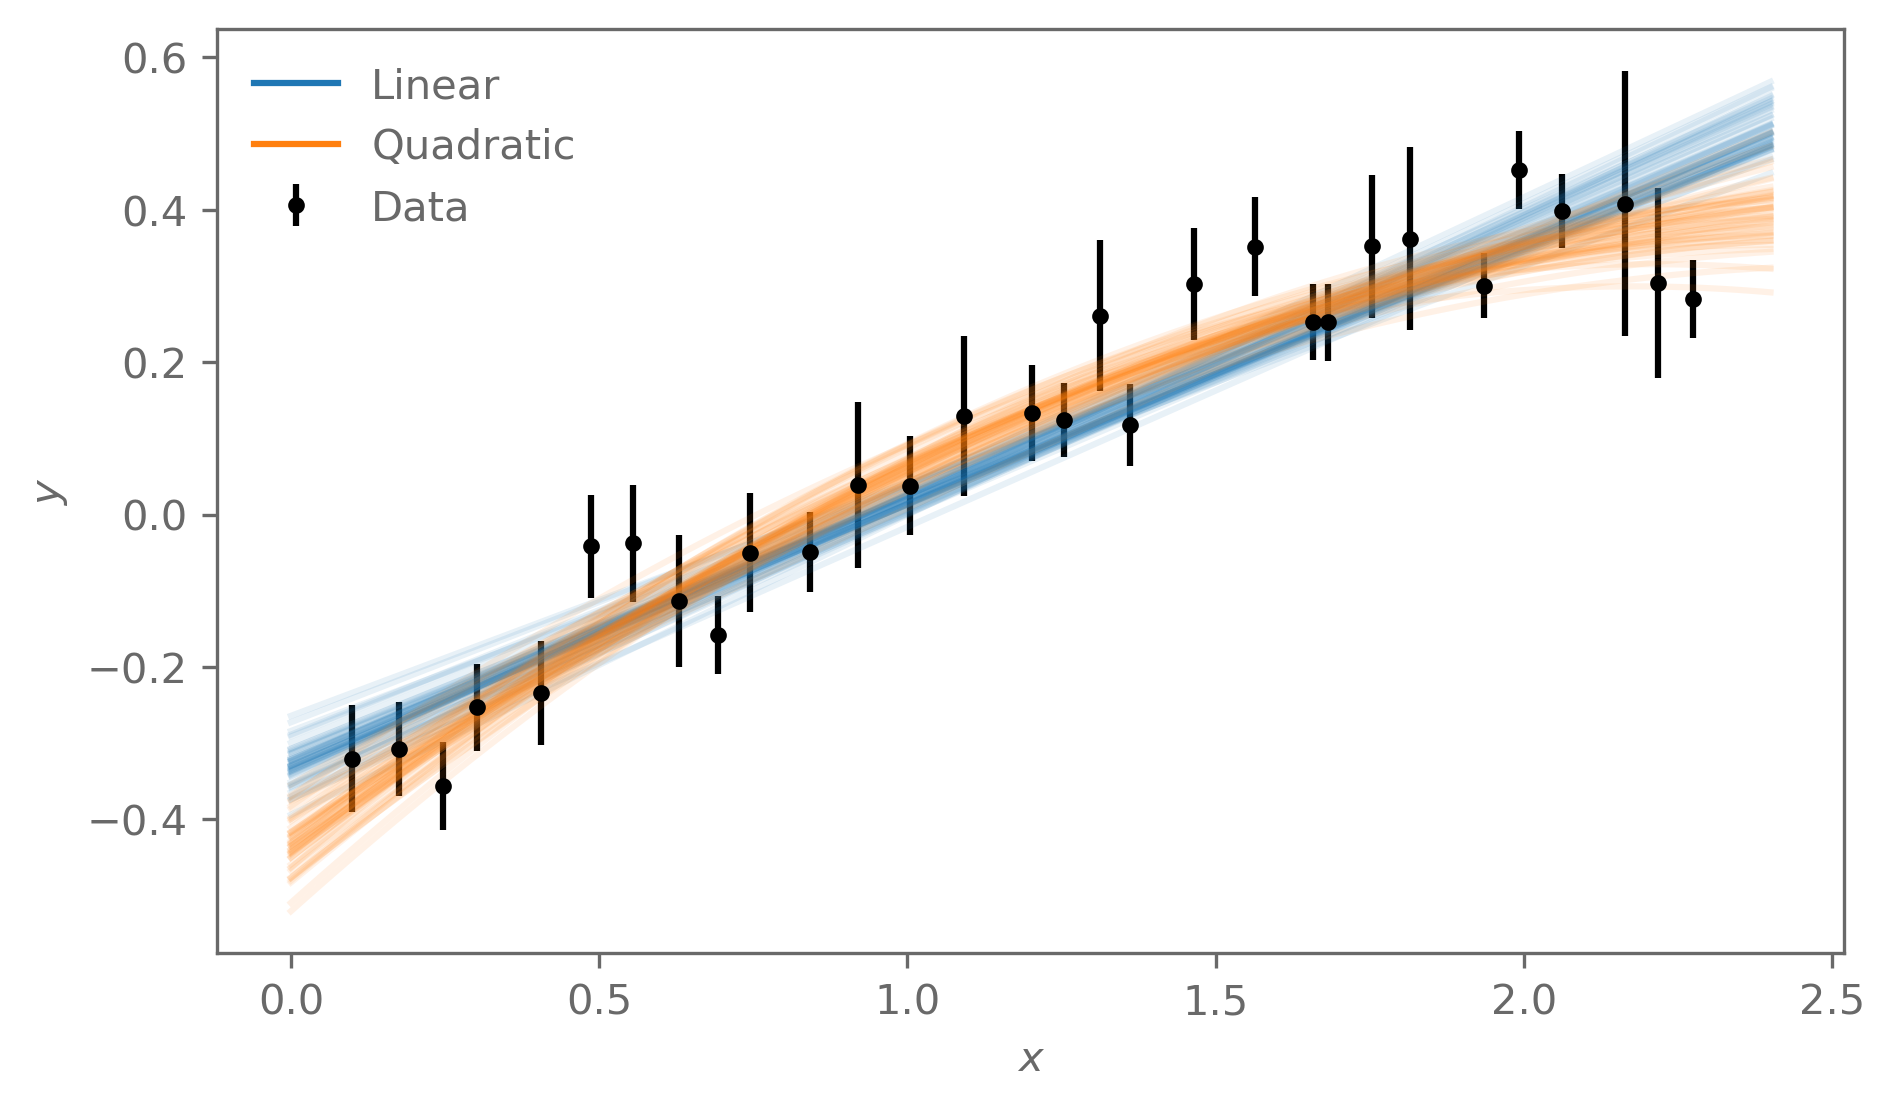

In [29]:
def plot_posterior_models(results_1, results_2, x, y, y_err):
    x_grid = np.linspace(0, 2.4, 100)
    plt.errorbar(x, y, y_err, fmt=".", c="k", label="Data")
    for results, model, color, label in [
        (results_1, linear_model, "C0", "Linear"),
        (results_2, quadratic_model, "C1", "Quadratic"),
    ]:
        samples = results.samples_equal()
        for theta in samples[:50]:
            plt.plot(x_grid, model(theta, x_grid), c=color, alpha=0.1)
        plt.plot([], [], c=color, label=label)
    plt.xlabel("$x$")
    plt.ylabel("$y$")
    plt.legend(frameon=False)

plot_posterior_models(results_linear, results_quadratic, x, y, y_err)

The quadratic model is preferred, with odds of about 7 to 1 ($R\approx 7$). With an uncertainty of about 0.4 on $\ln R$, this is a clear but not overwhelming preference.

In the plot, the quadratic model follows the bend in the data at small and large $x$.

### 5.2 Linear vs. quadratic model on `data_0.txt`

Linear:    ln Z_1 = -8.31 ± 0.20
Quadratic: ln Z_2 = -10.61 ± 0.24
ln R = -2.30 ± 0.31, R = 0.1


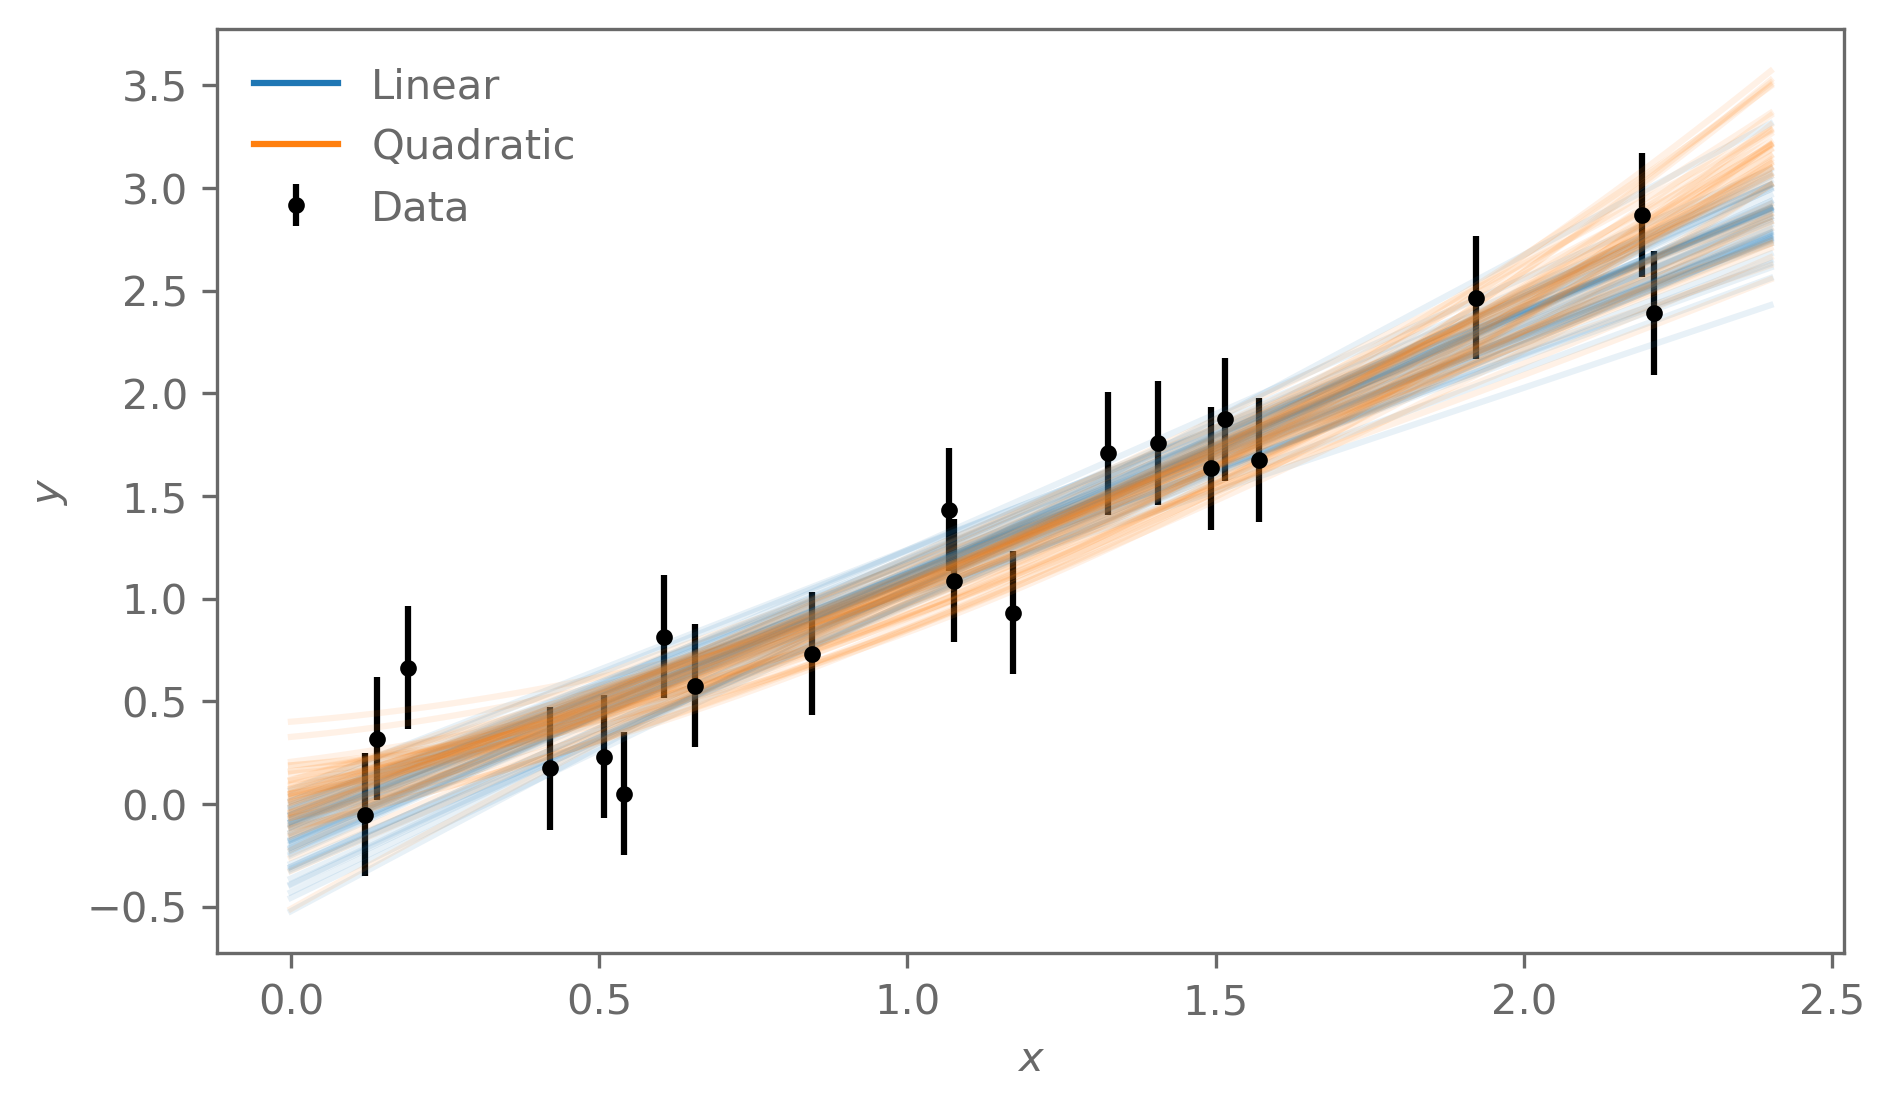

In [30]:
x_0, y_0, y_err_0 = np.loadtxt("../lectures/data/linear_fits/data_0.txt", unpack=True)

results_linear_0 = run_dynesty(linear_model, 2, prior_transform, x_0, y_0, y_err_0, seed=12)
results_quadratic_0 = run_dynesty(quadratic_model, 3, prior_transform, x_0, y_0, y_err_0, seed=13)

bayes_ratio(results_linear_0, results_quadratic_0)
plot_posterior_models(results_linear_0, results_quadratic_0, x_0, y_0, y_err_0)

Now the linear model is preferred, with odds of about 10 to 1.

The quadratic model fits these data just as well (its posterior on $a$ is consistent with 0), but it spreads its prior over many values of $a$ that do not fit the data. The evidence penalises this extra freedom (Occam's razor).

### 5.3 A wider prior on $a$

The prior on $a$ is now $\Uniform(-30, 30)$; $b$ and $c$ keep $\Uniform(-3, 3)$. Only $Z_2$ changes.

In [31]:
def prior_transform_wide_a(u):
    theta = 6*u - 3              # b and c: U(-3, 3)
    theta[0] = 60*u[0] - 30      # a: U(-30, 30)
    return theta

results_quadratic_wide = run_dynesty(quadratic_model, 3, prior_transform_wide_a, x, y, y_err, seed=14)

bayes_ratio(results_linear, results_quadratic_wide)

Linear:    ln Z_1 = 21.61 ± 0.25
Quadratic: ln Z_2 = 20.85 ± 0.32
ln R = -0.76 ± 0.41, R = 0.5


Did the posterior change?

In [32]:
samples_narrow = results_quadratic.samples_equal()
samples_wide = results_quadratic_wide.samples_equal()

for k, name in enumerate(["a", "b", "c"]):
    print(f"{name}: narrow prior {np.mean(samples_narrow[:, k]):.3f} ± {np.std(samples_narrow[:, k]):.3f}, "
          f"wide prior {np.mean(samples_wide[:, k]):.3f} ± {np.std(samples_wide[:, k]):.3f}")

print(f"Change in ln Z_2: {results_quadratic_wide.logz[-1] - results_quadratic.logz[-1]:.2f}")
print(f"-ln(10) = {-np.log(10):.2f}")

a: narrow prior -0.105 ± 0.032, wide prior -0.105 ± 0.031
b: narrow prior 0.599 ± 0.076, wide prior 0.598 ± 0.077
c: narrow prior -0.434 ± 0.038, wide prior -0.434 ± 0.039
Change in ln Z_2: -2.66
-ln(10) = -2.30


The posterior does not change, but $\ln Z_2$ drops by about $\ln 10$ (within the uncertainty of about 0.4). The prior on $a$ is 10 times wider, so the prior density where the likelihood is large is 10 times smaller ($Z\propto 1/V$, see the lecture).

Now the linear model is weakly preferred. The Bayes' ratio depends on the prior, even when the posterior does not, so priors have to be chosen carefully when comparing models.